# Moving atoms by linear phase interpolation: the sequence of holograms of a sort

**Question:** Once the assignment is fixed, does the sequence of holograms that M16 builds by linear phase interpolation keep the moving traps bright, and does it do better than computing every step on its own?

- Level: 3, state of the art. Method run: M16.
- Prerequisites: `07-feedback-and-dynamics/02-assigning-atoms-to-sites`, which builds the assignment and the plan.
- Reading time: about 30 minutes. The notebook runs in about a minute.

## Objectives

Moving a trap with an SLM means displaying a sequence of holograms. If each hologram is computed on its own, the free phases of the traps are whatever the algorithm finds, they jump from one step to the next, and the light that two neighbouring spots add at the position of a moving spot changes with them: the spot flickers, and an atom can be lost. Linear phase interpolation (LPI) is the published answer, and M16 implements it. By the end you can:

- say how LPI builds the intermediate holograms of a move from the two end holograms;
- measure the dip of every moving trap along the sequence for two exponents of the assignment;
- compare LPI with an independent hologram for every step, on the same moves;
- say what a finer step does to the dips;
- say which part of the answer is a model and which is a measurement.

## Setup


The notebook environment is pinned in `notebooks/requirements.txt` and built with `scripts/setup.sh --notebooks`
(`scripts/setup.ps1 -Notebooks` on Windows). This notebook uses two packages, at these exact pins:

```bash
pip install numpy==2.4.6 matplotlib==3.11.2
```

DinHot publishes no package of its own: its methods live in the pipeline folder `data-pipeline/`, and the next cell puts
that folder on the import path and imports the functions the notebook calls.

In [1]:
# the tools, their versions, and the pipeline folder on the import path
import sys
from dataclasses import replace
from importlib.metadata import version
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline.cases import build
from pipeline.cases.library import random_loading
from pipeline.io.contract import read_cases
from pipeline.model.holo.core.forward import point_trap_fields
from pipeline.model.holo.core.rng import Rng
from pipeline.model.holo.core.types import Budget, Target
from pipeline.model.holo.core.traps import TrapSet
from pipeline.model.holo.methods.baseline import m07_phase_fixed_wgs
from pipeline.model.holo.methods.beyond.b2_flicker_bounded import trajectory, transient_min_ratio
from pipeline.model.holo.methods.control import m16_rearrangement

print("numpy", version("numpy"), "| matplotlib", version("matplotlib"))

numpy 2.4.6 | matplotlib 3.11.2


## Data

The notebook reads case C10 of `data/examples/cases.json`: a 10 x 10 array of sites with a spacing of about 8 focal bins, a loading probability of 0.55 and a block of 36 target sites in the middle.

- Owner: this repository; the case is synthetic, and the loading is drawn from the portable generator with the seed of the record.
- Licence class: generated data under the repository's own licence, no third-party dataset.
- File: `data/examples/cases.json`, case C10 (the `rearrangement` block carries the loading probability, the target ids and the exponent).

In [2]:
# case C10: a 10 x 10 site array, loaded at random, and a 6 x 6 block to be filled
rec = {c["case_id"][:3]: c for c in read_cases(ROOT / "data/examples/cases.json")}["C10"]
setup = build.setup_of(rec)
sites = {t["id"]: t for t in rec["target"]["traps"]}
loaded = random_loading(rec)
wanted = rec["rearrangement"]["target_ids"]
empty = sorted(set(wanted) - set(loaded))
surplus = sorted(set(loaded) - set(wanted))
print(rec["case_id"], "|", len(sites), "sites | loading probability", rec["rearrangement"]["loading_p"])
print(f"loaded atoms: {len(loaded)} | target sites: {len(wanted)} | "
      f"empty target sites: {len(empty)} | surplus atoms: {len(surplus)}")

C10_rearrangement | 100 sites | loading probability 0.55
loaded atoms: 52 | target sites: 36 | empty target sites: 16 | surplus atoms: 32


## Method

M16 computes the hologram of the starting positions and the hologram of the final ones, both with phase-fixed weighted GS (Kim et al., 2019), reads from each the position, amplitude and optical phase of every tweezer, and builds the frames in between by interpolating them linearly over $S$ steps: $x_m(s) = x_m^\text{i} + (s/S)(x_m^\text{f} - x_m^\text{i})$ for the position, the same for the amplitude, and for the phase the wrapped difference, $\psi_m(s) = \psi_m^\text{i} + (s/S)\,\mathrm{wrap}(\psi_m^\text{f} - \psi_m^\text{i})$. Every frame is the inverse transform of the superposition of the interpolated spots, with no optimisation of its own (the arXiv 2501.01391 recipe; the wrapped phase difference is the pipeline's reading of it). The number of steps is $S = \lceil d_\text{max} / s_\text{max} \rceil$ with the longest move $d_\text{max}$ and a step $s_\text{max}$ of two bins by default. The sort is the one of the previous notebook, case C10: 52 loaded atoms, 36 target sites.

## State of the art

LPI is the state of the art for the light of a sort, and its authors report that the moving traps stay above 70 percent of their intensity where independent weighted-GS holograms make the spot almost vanish. No pinned reference implementation of it exists among the notebook dependencies (slmsuite provides no sequence of moving holograms), so the baseline here is the one the paper compares with, an independent hologram for every step, computed with DinHot's own M07. The cells run M16 for the two exponents and measure the dips.

### The sequence of holograms

Knowing the paths, the light must follow them. The cell runs M16, as the Method section describes it, for the plan with $\alpha = 1.0$: end holograms of 30 iterations each and a step of two bins, one Fourier unit.

In [3]:
# M16 on the same sort with alpha = 1.0: two phase-fixed WGS holograms and the linear phase interpolation
# between them
atoms = build.trapset_of([sites[i] for i in loaded])
goal = Target.from_traps(build.trapset_of([sites[i] for i in wanted]))
seq10 = m16_rearrangement.run(setup, goal, budget=Budget(30), rng=Rng(1), atoms=atoms, alpha=1.0)
moving10 = seq10.meta["moved"]
ratio10 = seq10.meta["min_ratio"][moving10]
print(f"alpha 1.0: {seq10.meta['n_steps']} steps | {int(moving10.sum())} moving traps | "
      f"crossings {seq10.meta['crossings']}")
print(f"lowest intensity of a moving trap, relative to its mean: "
      f"min {ratio10.min():.3f}, median {np.median(ratio10):.3f}")

alpha 1.0: 15 steps | 16 moving traps | crossings 0
lowest intensity of a moving trap, relative to its mean: min 0.743, median 0.841


The sort with $\alpha = 1.0$ takes 15 steps for its 16 moving traps, 0 crossings, and the lowest intensity that a moving trap reaches, relative to its own mean over the sequence, is 0.743 (median 0.841). The same sequence for the exponent of Lee, Kim and Ahn follows.

In [4]:
# the same with alpha = 1.5, the value of Lee, Kim and Ahn
seq15 = m16_rearrangement.run(setup, goal, budget=Budget(30), rng=Rng(1), atoms=atoms, alpha=1.5)
moving15 = seq15.meta["moved"]
ratio15 = seq15.meta["min_ratio"][moving15]
print(f"alpha 1.5: {seq15.meta['n_steps']} steps | {int(moving15.sum())} moving traps | "
      f"crossings {seq15.meta['crossings']}")
print(f"lowest intensity of a moving trap, relative to its mean: "
      f"min {ratio15.min():.3f}, median {np.median(ratio15):.3f}")
print(f"share of moving traps that stay above 0.7: "
      f"{np.mean(ratio10 >= 0.7):.3f} (alpha 1.0), {np.mean(ratio15 >= 0.7):.3f} (alpha 1.5)")

alpha 1.5: 9 steps | 24 moving traps | crossings 1
lowest intensity of a moving trap, relative to its mean: min 0.651, median 0.836
share of moving traps that stay above 0.7: 1.000 (alpha 1.0), 0.958 (alpha 1.5)


With $\alpha = 1.5$ the sequence needs only 9 steps, because the longest move is shorter, and it moves 24 traps. The lowest intensity of a moving trap is 0.651 (median 0.836), and 95.8 percent of the moving traps stay above 0.7, one trap of 24 below it, against all of them for $\alpha = 1.0$. The 0.7 line of the paper is the one to compare with.

To see a single dip, the next cell takes the weakest moving trap of the $\alpha = 1.5$ sequence and computes its intensity from the field of every frame, at the position that the frame gives it.

In [5]:
# the intensity of the weakest moving trap of the alpha = 1.5 sequence at every step, from the frames' own
# fields
weakest = int(np.flatnonzero(moving15)[np.argmin(ratio15)])
frames, steps_15 = seq15.meta["frames"], seq15.meta["trap_sequence"]
along = np.array([abs(point_trap_fields(frames[s], setup, steps_15[s])[weakest]) ** 2 for s in range(len(frames))])
allm = np.array([np.abs(point_trap_fields(frames[s], setup, steps_15[s])) ** 2 for s in range(len(frames))])
print(f"weakest moving trap, index: {weakest} | mean over the sequence "
      f"{along.mean():.4f} | lowest {along.min():.4f}")
print(f"mean intensity of all 36 traps: {allm.mean():.4f}")

weakest moving trap, index: 12 | mean over the sequence 0.0201 | lowest 0.0131
mean intensity of all 36 traps: 0.0200


The left panel plots that trap's intensity against the step, relative to its mean over the sequence, and the right panel histograms the lowest relative intensity of every moving trap for the two exponents.

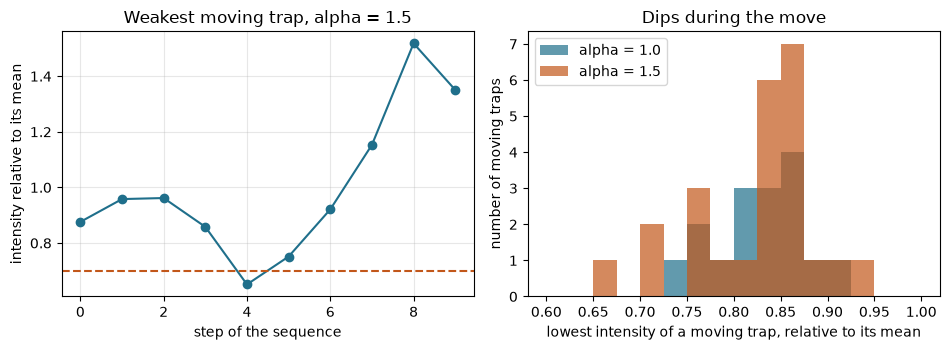

In [6]:
# intensity of the weakest moving trap against the step, with the mean over the sequence and the 70 % line
fig, (a, b) = plt.subplots(1, 2, figsize=(9.6, 3.6))
a.plot(along / along.mean(), "o-", color="#1f6f8b")
a.axhline(0.7, color="#c2571a", linestyle="--")
a.set_xlabel("step of the sequence")
a.set_ylabel("intensity relative to its mean")
a.set_title("Weakest moving trap, alpha = 1.5")
a.grid(True, alpha=0.3)
b.hist(ratio10, bins=np.linspace(0.6, 1.0, 17), alpha=0.7, label="alpha = 1.0", color="#1f6f8b")
b.hist(ratio15, bins=np.linspace(0.6, 1.0, 17), alpha=0.7, label="alpha = 1.5", color="#c2571a")
b.set_xlabel("lowest intensity of a moving trap, relative to its mean")
b.set_ylabel("number of moving traps")
b.set_title("Dips during the move")
b.legend()
plt.tight_layout()
plt.show()

The weakest trap has a mean intensity of 0.0201 over the sequence, close to the 0.0200 mean of all 36 traps, and falls to 0.0131 at step 4, the fifth frame, a dip to 0.65 of its mean. After the dip it rises to about 1.5 times its mean at step 8 and ends at 1.35. The histogram has two overlapping distributions that peak between 0.85 and 0.875; the sequence of $\alpha = 1.5$ has a longer left tail, down to 0.65, because it moves more traps, while that of $\alpha = 1.0$ stops at about 0.73. The figure shows that LPI keeps the moving traps above 0.7 in all but one case, and it does not show anything about the instants between two frames, where the liquid crystal is still relaxing; the notebook on flicker-bounded moves adds that model. It also shows one loading and one seed.

### The baseline: an independent hologram for every step

For the 9 steps (10 frames) of the $\alpha = 1.5$ sequence the cell computes a separate phase-fixed WGS hologram at the positions of that step, with 30 iterations, as the end holograms of LPI get, and no link to its neighbours. Each of them is perfect at its own step, so the flicker is not in the frames but between them, and the measure has to include the blend of two consecutive frames. The cell scores both sequences with the transient model of B2, which blends frame $s$ and frame $s+1$ and reads each trap at its position in between, with positions that are linear in the step, and prints the lowest intensity of each moving trap relative to its mean.

In [7]:
# the alternative to LPI: an independent phase-fixed WGS hologram (30 iterations) for every step of the
# alpha = 1.5 sequence
order = seq15.meta["assignment"]
origin = TrapSet(replace(t, x_m=atoms.x_m[order[i]], y_m=atoms.y_m[order[i]]) for i, t in enumerate(goal.traps))
blend_path = trajectory(origin, goal.traps, len(steps_15), profile=lambda tau: tau)
free = [m07_phase_fixed_wgs.run(setup, Target.from_traps(ts), budget=Budget(30), rng=Rng(7)).phi for ts in steps_15]
ratios = {"LPI (M16)": transient_min_ratio(setup, list(frames), blend_path)[moving15],
          "independent WGS": transient_min_ratio(setup, free, blend_path)[moving15]}
for name, r in ratios.items():
    print(f"{name:22s} lowest {r.min():.3f} | median {np.median(r):.3f} | "
          f"share of moving traps at or above 0.7 {np.mean(r >= 0.7):.3f}")

LPI (M16)              lowest 0.435 | median 0.665 | share of moving traps at or above 0.7 0.375
independent WGS        lowest 0.163 | median 0.643 | share of moving traps at or above 0.7 0.292


The figure sorts the lowest intensity of every moving trap, for both sequences.

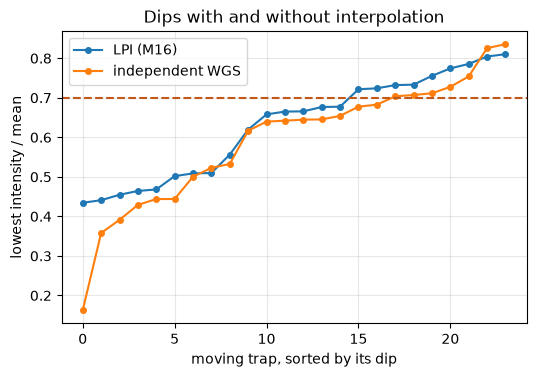

In [8]:
# the lowest intensity of every moving trap in each sequence, sorted
fig, ax = plt.subplots(figsize=(6.0, 3.8))
for name, r in ratios.items():
    ax.plot(np.sort(r), "o-", markersize=4, label=name)
ax.axhline(0.7, color="#c2571a", linestyle="--")
ax.set_xlabel("moving trap, sorted by its dip")
ax.set_ylabel("lowest intensity / mean")
ax.set_title("Dips with and without interpolation")
ax.legend()
ax.grid(True, alpha=0.3)
plt.show()

Under the blend model LPI has a worst moving trap at 0.435 of its mean, a median of 0.665 and 37.5 percent of the moving traps at or above 0.7; the independent holograms, given the same 30 iterations as the end holograms of LPI, have a worst trap at 0.163, a median of 0.643 and 29.2 percent at or above 0.7. The two sequences are close in the middle of the distribution and differ most in its tail: LPI keeps its worst trap 2.7 times higher than the independent holograms, which is what the paper reports, the spot that almost vanishes. The blend model is stricter than the frame-only measure of the earlier cells (a worst trap of 0.651 for the same LPI frames), because it counts the instants between frames, and it is the pipeline's reading of the paper, marked unverified in the method. The figure shows one sequence and one seed, so it does not say how robust the factor of 2.7 is.

A smaller step gives LPI more frames over the same move. The cell runs M16 again for the exponent 1.5 with at most one bin per step, in place of two.

In [9]:
# LPI with a finer step: at most one bin per step instead of two, for alpha = 1.5
seq_fine = m16_rearrangement.run(setup, goal, budget=Budget(30), rng=Rng(1), atoms=atoms, alpha=1.5, max_step_bins=1.0)
ratio_fine = seq_fine.meta["min_ratio"][seq_fine.meta["moved"]]
print(f"{seq_fine.meta['n_steps']} steps | lowest intensity of a moving trap, relative to its mean "
      f"{ratio_fine.min():.3f} | median {np.median(ratio_fine):.3f} | "
      f"share at or above 0.7 {np.mean(ratio_fine >= 0.7):.3f}")

18 steps | lowest intensity of a moving trap, relative to its mean 0.652 | median 0.834 | share at or above 0.7 0.958


With a step of one bin the sequence has 18 steps, but the lowest intensity of a moving trap does not rise: it is 0.652 against 0.651 with the step of two bins, and 95.8 percent of the moving traps stay at or above 0.7 in both; the median is 0.834 against 0.836. A finer step doubles the number of holograms and changes nothing in the dips of the frames, so the weakest trap's dip is not a matter of step size on this sort. The measure is the frame-only one of M16, so the result does not say what the blends between frames would show.

## Results

**Answer:** On the frame-only measure M16 keeps the moving traps near the 0.7 line of the paper (lowest 0.651 to 0.743); under the stricter blend model it does not (median 0.665, 37.5 percent at or above 0.7, against 29.2 for independent holograms) and beats the independent holograms mainly in the worst trap (0.435 against 0.163). On the sort of case C10, the sequence of the exponent 1.0 has 15 steps and 16 moving traps whose lowest intensity along the frames is 0.743 of their mean (median 0.841, all above 0.7), and that of the exponent 1.5 has 9 steps and 24 moving traps with a lowest of 0.651 (median 0.836, 95.8 percent above 0.7). A finer step of at most one bin gives 18 steps and the same dips, a lowest of 0.652.

What the notebook does not show is an independent implementation of LPI, which does not exist among the dependencies, or the loss of an atom that the dips could cause.

## Summary

- LPI builds the frames of a move by interpolating position, amplitude and phase between two end holograms, with no optimisation of the frames.
- The number of steps follows the longest move of the assignment: 15 at the exponent 1.0 and 9 at 1.5.
- On the frames the weakest moving trap dips to 0.74 (alpha 1.0) and 0.65 (alpha 1.5) of its mean, with medians of 0.84, around the 0.7 of the paper; under the blend model, which counts the instants between frames, only 37.5 percent of them stay at or above 0.7.
- Independent holograms for every step, the baseline of the paper, have a worst moving trap at 0.163 against 0.435 for LPI under the blend model.
- No pinned reference implementation of M16 exists among the dependencies.

## References

- Lee, Kim and Ahn (2017). Defect-free atomic array formation using the Hungarian matching algorithm. Physical Review A 95, 053424. https://doi.org/10.1103/PhysRevA.95.053424
- Parallel assembly of neutral atom arrays with an SLM using linear phase interpolation. https://arxiv.org/abs/2501.01391